In [1]:
import torch
from torch import nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch_directml

In [ ]:
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100

LEARNING_RATE = 1e-4
BETA1 = 0.0
BETA2 = 0.9
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10
EPOCHS = 25

GEN_FEATURES = 64
DISC_FEATURES = 64

DEVICE = torch_directml.device()

NUM_CLASSES = 6

In [3]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = torchvision.datasets.ImageFolder(root='data/intel-image/train', transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.label_embedding = nn.Embedding(NUM_CLASSES, LATENT_DIM)

        self.main = nn.Sequential(
            # ---Block 1: From noise (1x1) to small image (4x4)---
            nn.ConvTranspose2d(in_channels=LATENT_DIM * 2, out_channels=GEN_FEATURES * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 8),
            nn.ReLU(inplace=True),
            # Output: [512, 4, 4]

            # ---Block 2: From 4x4 to 8x8---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 8, out_channels=GEN_FEATURES * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 4),
            nn.ReLU(inplace=True),
            # Output: [256, 8, 8]

            # ---Block 3: From 8x8 to 16x16---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 4, out_channels=GEN_FEATURES * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 2),
            nn.ReLU(inplace=True),
            # Output: [128, 16, 16]

            # ---Block 4: From 16x16 to 32x32---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 2, out_channels=GEN_FEATURES, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES),
            nn.ReLU(inplace=True),
            # Output: [64, 32, 32]

            # ---Block 5: From 32x32 to 64x64---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES, out_channels=CHANNELS, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
            # Output: [3, 64, 64]
        )

    def forward(self, x, labels):
        c = self.label_embedding(labels).unsqueeze(2).unsqueeze(3)
        x = torch.cat([x, c], dim=1)
        return self.main(x)


In [ ]:
class Critic(nn.Module):
    def __init__(self):
        super().__init__()

        self.label_embedding = nn.Embedding(NUM_CLASSES, 1)

        self.main = nn.Sequential(
            nn.Conv2d(CHANNELS + 1, DISC_FEATURES, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES, DISC_FEATURES * 2, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES * 2, DISC_FEATURES * 4, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES * 4, DISC_FEATURES * 8, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(DISC_FEATURES * 8, 1, 4, 1, 0, bias=False),
        )

    def forward(self, x, labels):
        c = self.label_embedding(labels).unsqueeze(2).unsqueeze(3)
        c = c.expand(-1, -1, IMAGE_SIZE, IMAGE_SIZE)

        x = torch.cat([x, c], dim=1)
        
        return self.main(x).view(-1)

In [6]:
netG = Generator().to(DEVICE)
netC = Critic().to(DEVICE)

In [7]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG.apply(weights_init)
netC.apply(weights_init)

optimizerG = torch.optim.Adam(netG.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
optimizerC = torch.optim.Adam(netC.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

In [ ]:
def compute_gradient_penalty(netC, real_samples, fake_samples, labels):
    alpha = torch.rand((real_samples.size(0), 1, 1, 1), device=DEVICE)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    d_interpolates = netC(interpolates, labels)
    fake = torch.ones((real_samples.shape[0],), device=DEVICE)

    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients = gradients.view(gradients.size(0), -1)
    gradient_norm = gradients.norm(2, dim=1)

    gradient_penalty = ((gradient_norm - 1) ** 2).mean()
    return gradient_penalty

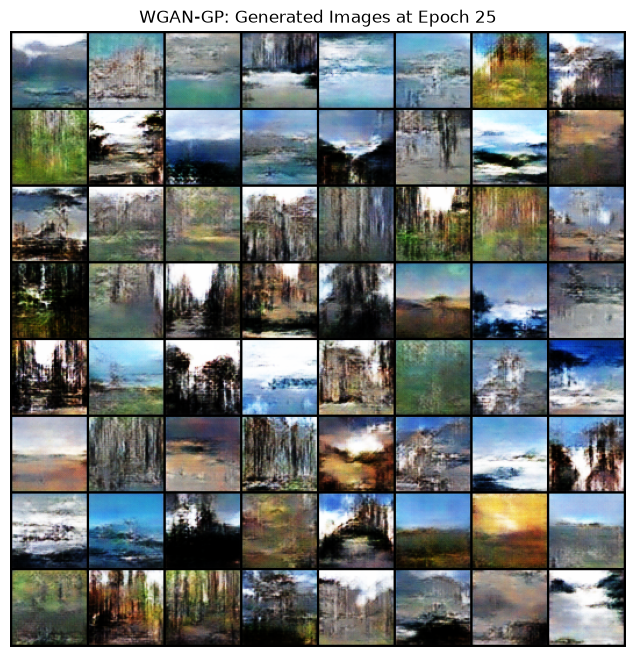

In [ ]:
from IPython.display import clear_output

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=DEVICE)

Wasserstein_distances = []

for epoch in range(EPOCHS):
    for i, data in enumerate(dataloader, 0):
        real_images = data[0].to(DEVICE)
        real_labels = data[1].to(DEVICE)
        cur_batch_size = real_images.size(0)

        # --- Phase 1: Critic Training ---
        for _ in range(CRITIC_ITERATIONS):
            netC.zero_grad()
            real_critic_score = netC(real_images, real_labels)

            noise = torch.randn(cur_batch_size, LATENT_DIM, 1, 1, device=DEVICE)
            fake_labels = torch.randint(0, NUM_CLASSES, (cur_batch_size,), device=DEVICE)
            fake_images = netG(noise, fake_labels)
            fake_critic_score = netC(fake_images.detach(), fake_labels)

            gp = compute_gradient_penalty(netC, real_images, fake_images.detach(), real_labels)

            loss_C = fake_critic_score.mean() - real_critic_score.mean() + LAMBDA_GP * gp
            loss_C.backward()
            optimizerC.step()

        # --- Phase 2: Generator Training ---
        netG.zero_grad()

        noise = torch.randn(cur_batch_size, LATENT_DIM, 1, 1, device=DEVICE)
        fake_labels = torch.randint(0, NUM_CLASSES, (cur_batch_size,), device=DEVICE)
        fake_images = netG(noise, fake_labels)

        fake_critic_score = netC(fake_images, fake_labels)

        loss_G = -fake_critic_score.mean()
        loss_G.backward()
        optimizerG.step()

        w_dist = (real_critic_score.mean() - fake_critic_score.mean()).item()
        Wasserstein_distances.append(w_dist)

        if i % 100 == 0:
            print(f"[{epoch}/{EPOCHS}][{i}/{len(dataloader)}] "
                  f"Critic Loss: {loss_C.item():.4f} | Generator Loss: {loss_G.item():.4f} | "
                  f"Wasserstein Distance: {w_dist:.4f}")

    with torch.no_grad():
        fixed_labels = torch.randint(0, NUM_CLASSES, (64,), device=DEVICE)
        fake_test = netG(fixed_noise, fixed_labels).detach().cpu()

    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.axis("off")
    plt.title(f'WGAN-GP: Generated Images at Epoch {epoch + 1}')
    plt.imshow(np.transpose(torchvision.utils.make_grid(fake_test, padding=2, normalize=True), (1, 2, 0)))
    plt.show()

torch.save(netG.state_dict(), 'wgangp_intel.pth')
            

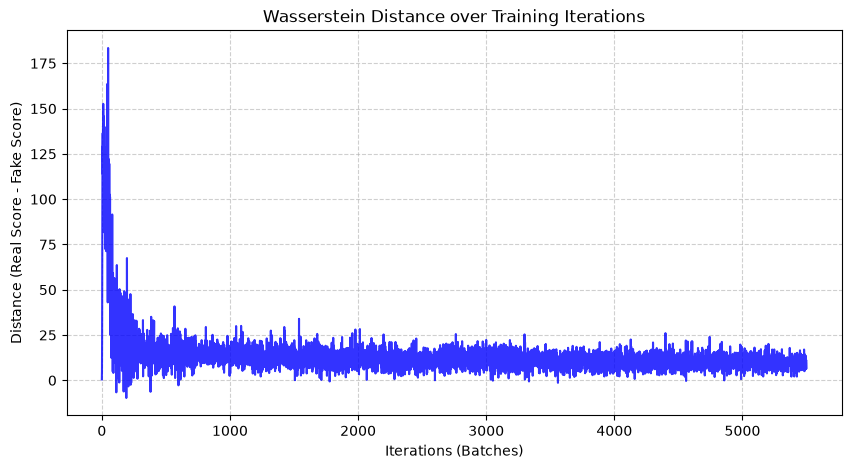

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(Wasserstein_distances, color='blue', alpha=0.8)
plt.title("Wasserstein Distance over Training Iterations")
plt.xlabel("Iterations (Batches)")
plt.ylabel("Distance (Real Score - Fake Score)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
def generate_class_samples(model, class_label, num_samples=16):
    device = next(model.parameters()).device
    
    model.eval()
    
    noise = torch.randn(num_samples, LATENT_DIM, 1, 1, device=device)
    labels = torch.full((num_samples,), class_label, dtype=torch.long, device=device)
    
    with torch.no_grad():
        generated_images = model(noise, labels).cpu()
    
    nrow = int(num_samples ** 0.5)
    grid = torchvision.utils.make_grid(generated_images, nrow=nrow, padding=2, normalize=True)
    
    plt.figure(figsize=(8, 8))
    plt.axis("off")
    plt.title(f"Wygenerowane próbki dla klasy: {class_label}")
    
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()
    

generate_class_samples(netG, class_label=2, num_samples=16)